The code for getting the data from the frost API is based on the official MET guide (how to work with Frost using Python)
It was moderized using AI, which is stated in the AI transcript document, to more effectively build the dataframe.

In [2]:
import requests
import pandas as pd
import os
from dotenv import load_dotenv

# Laster inn .env-filen
load_dotenv()
client_id = os.getenv("FROST_CLIENT_ID")

def fetch_frost_data(sources, elements, referencetime):
    """this function will create a pandas dataframe from the frost API"""
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
    }



    r = requests.get(endpoint, parameters, auth=(client_id, ''))

    if r.status_code == 200:
        data = r.json()['data']
    else:
        print(f"Feil: {r.status_code}")
        print(r.json()) # Skriver ut feilmelding fra API-et
        return None

# MODERNISERT OG RASKERE MÅTE Å BYGGE DATAFRAME PÅ:
    rows = []
    for item in data:
        ref_time = item['referenceTime']
        source_id = item['sourceId']
        for obs in item['observations']:
            # Kopierer felles metadata inn i hver observasjon
            obs['referenceTime'] = ref_time
            obs['sourceId'] = source_id
            rows.append(obs)

    df = pd.DataFrame(rows)

# Beholder kun relevante kolonner og rydder i tid
    columns = ['sourceId', 'referenceTime', 'elementId', 'value', 'unit', 'timeOffset']
    df = df[columns].copy()
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

# Sorter kronologisk (viktig for plotting og rullende gjennomsnitt senere!)
    df = df.sort_values('referenceTime').reset_index(drop=True)

    return df




**task 1**



In [4]:
df_temp_2025 = fetch_frost_data(
    sources='SN17850', 
    elements='mean(air_temperature P1D)', 
    referencetime='2025-01-01/2025-12-31')

df.plot(x = 'referenceTime', y = 'value', title = 'mean temp 2025')

summary = df_temp_2025['value'].agg(['mean', 'min', 'max', 'std'])
summary = summary.round(2)

print("summary temperatures 2025:")
print(summary)

NameError: name 'df' is not defined

## Task 2: Precipitation

In [4]:
def get_daily_values(sources, elements, referencetime):
    """Request daily values from Frost and return a DataFrame
    with Time as index and one column, value (as in lecture 5)."""
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
    }
    response = requests.get(endpoint, parameters, auth=(client_id, ""))
    assert response.status_code == 200   # 200 means everything went well

    payload = response.json()

    # Take only the first observation for each day
    records = [{'Time': pd.to_datetime(entry['referenceTime']),
                'value': entry['observations'][0]['value']}
               for entry in payload['data']]

    return pd.DataFrame.from_records(records).set_index('Time')

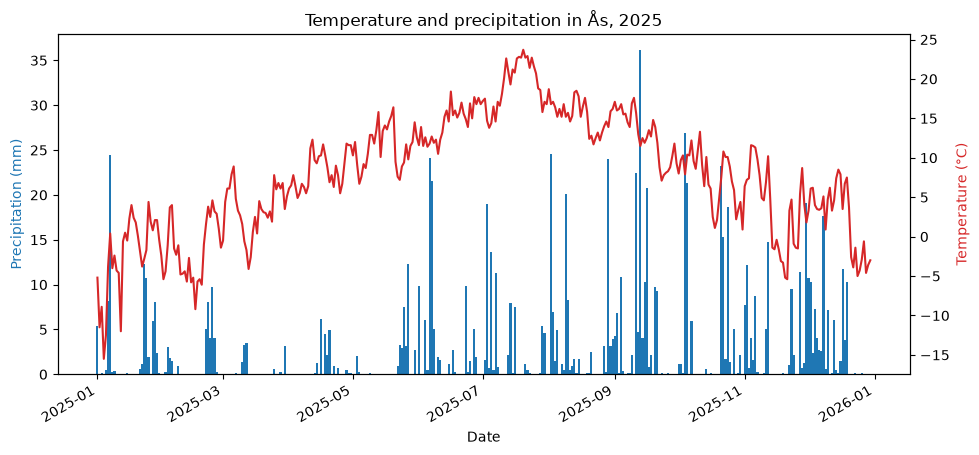

In [5]:
import matplotlib.pyplot as plt

# Daily precipitation in Ås for 2025 (sum over 24 hours)
prec_2025 = get_daily_values('SN17850', 'sum(precipitation_amount P1D)', '2025-01-01/2025-12-31')

# Temperature again, with the same function: one value per day.
# (We fetch it here so we don't change the Task 1 cells.)
temp_2025 = get_daily_values('SN17850', 'mean(air_temperature P1D)', '2025-01-01/2025-12-31')

fig, ax1 = plt.subplots(figsize=(11, 5))

# Precipitation as bars on the left y-axis
ax1.bar(prec_2025.index, prec_2025['value'], color='tab:blue', width=1.0)
ax1.set_xlabel('Date')
ax1.set_ylabel('Precipitation (mm)', color='tab:blue')

# Temperature as a line on a second y-axis on the right
ax2 = ax1.twinx()
ax2.plot(temp_2025.index, temp_2025['value'], color='tab:red')
ax2.set_ylabel('Temperature (°C)', color='tab:red')

ax1.set_title('Temperature and precipitation in Ås, 2025')
fig.autofmt_xdate()   # tilted the dates so they don't overlap
plt.show()

   ## Task 3: Historical temperature data

364


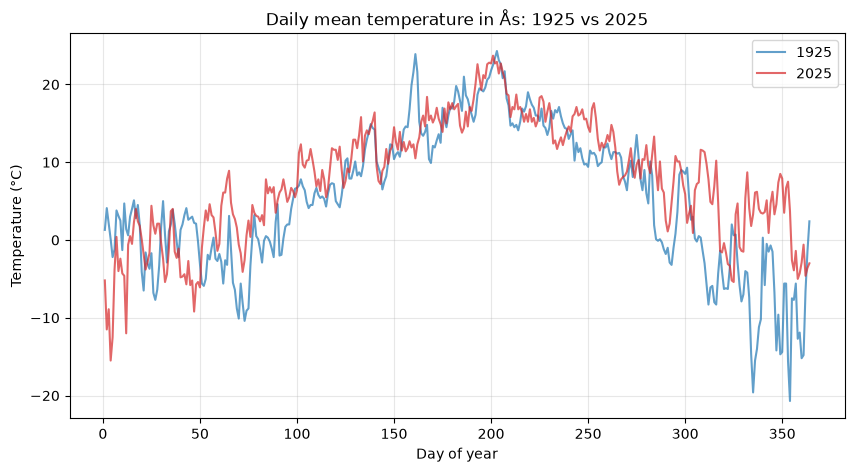

Summary of daily mean temperature in Ås (°C)
         1925  2025
mean     5.31   7.9
median   5.30   8.4
min    -20.70 -15.5
max     24.30  23.7


In [6]:
# Daily mean temperatur in Ås 100 years earlier (1925)
temp_1925 = get_daily_values('SN17850', 'mean(air_temperature P1D)', '1925-01-01/1925-12-31')
print(len(temp_1925))   # number of days we got

# temp_2025 comes from the Task 2 cell.
## Day of the year (1-365) puts both years on the same x-axis
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(temp_1925.index.dayofyear, temp_1925['value'], color='tab:blue', alpha=0.7, label='1925')
ax.plot(temp_2025.index.dayofyear, temp_2025['value'], color='tab:red', alpha=0.7, label='2025')
ax.set_title('Daily mean temperature in Ås: 1925 vs 2025')
ax.set_xlabel('Day of year')
ax.set_ylabel('Temperature (°C)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Summary table with both years 
summary = pd.DataFrame({
    '1925': temp_1925['value'].agg(['mean', 'median', 'min', 'max']),
    '2025': temp_2025['value'].agg(['mean', 'median', 'min', 'max']),
}).round(2)
print('Summary of daily mean temperature in Ås (°C)')
print(summary)

## Task 4: Heatwaves

In [7]:
import yaml


def count_heatwaves(station_id, year):
    """Find heatwaves (5+ days in a row with max temperature >= 27 °C),
    write a summary to a yml file and return the number of heatwaves."""
    # Daily maximum temperature for the whole year
    max_temp = get_daily_values(station_id, 'max(air_temperature P1D)',
                                f'{year}-01-01/{year}-12-31')

    ## Look up the station name in Frost
    response = requests.get('https://frost.met.no/sources/v0.jsonld',
                            {'ids': station_id}, auth=(client_id, ""))
    station_name = response.json()['data'][0]['name'].title()

    heatwaves = []   # finished heatwaves, as text
    run_dates = []   # the hot days in the current run

    for date, value in zip(max_temp.index, max_temp['value']):
        hot = value >= 27
        # Today continues the run if it is hot and comes right after the previous hot day
        if hot and (len(run_dates) == 0 or (date - run_dates[-1]).days == 1):
            run_dates.append(date)
        else:
            if len(run_dates) >= 5:   # the run has ended: was it long enough?
                heatwaves.append(f'{run_dates[0].date()} - {run_dates[-1].date()}')
            run_dates = [date] if hot else []   # a hot day starts a new run

    if len(run_dates) >= 5:   
        heatwaves.append(f'{run_dates[0].date()} - {run_dates[-1].date()}')

    # Write summary to a yml file 
    summary = {'dates': heatwaves, 'station_id': station_id,
               'station_name': station_name, 'year': year}
    with open(f'heatwave_summary_{station_id}_{year}.yml', 'w') as f:
        yaml.dump(summary, f)

    return len(heatwaves)


print(count_heatwaves('SN17850', 2025))

1


Check: To verify the heatwave result, we listed the days with a maximum temperature of 27 °C or more for both offsets Frost provides (PT0H and PT18H). Both give exactly one heatwave in 2025, so our result of 1 heatwave (16 to 20 July) does not depend on the offset.

In [8]:
# Which days have max temperature >= 27 °C, for each offset?
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'max(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31'}
payload = requests.get(endpoint, parameters, auth=(client_id, "")).json()

for offset in ['PT0H', 'PT18H']:
    hot_days = [entry['referenceTime'][:10]
                for entry in payload['data']
                for obs in entry['observations']
                if obs['timeOffset'] == offset and obs['value'] >= 27]
    print(offset, len(hot_days), 'hot days')
    for k in range(0, len(hot_days), 6):   # print 6 dates per line
        print(hot_days[k:k + 6])

PT0H 10 hot days
['2025-07-11', '2025-07-12', '2025-07-16', '2025-07-17', '2025-07-18', '2025-07-19']
['2025-07-20', '2025-07-22', '2025-07-24', '2025-07-25']
PT18H 11 hot days
['2025-07-11', '2025-07-12', '2025-07-16', '2025-07-17', '2025-07-18', '2025-07-19']
['2025-07-20', '2025-07-21', '2025-07-22', '2025-07-24', '2025-07-25']


## Task 5: Moving average temperature

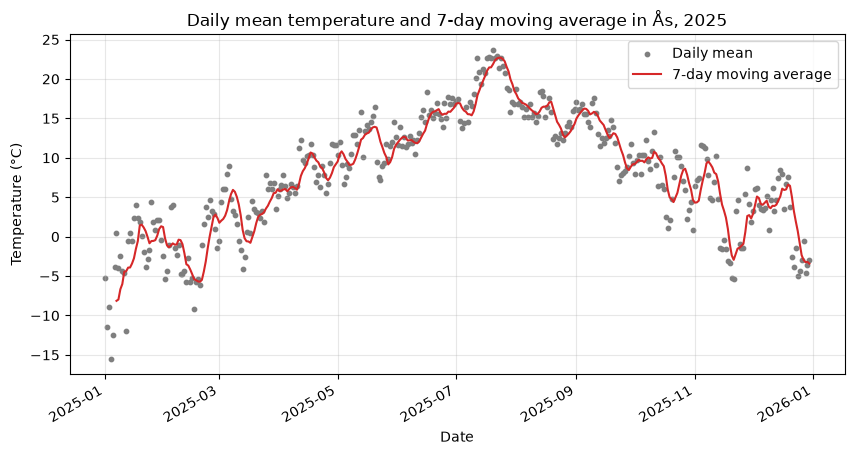

In [9]:
def moving_average(values, window=7):
    """Return the moving average over `window` days.
    The result starts on day `window`, the first day with enough earlier days."""
    values = list(values)
    return [sum(values[i - window + 1:i + 1]) / window
            for i in range(window - 1, len(values))]


## Use it on the 2025 mean temperature (temp_2025 from the Task 2 cell: one value per day)
average = moving_average(temp_2025['value'])

fig, ax = plt.subplots(figsize=(10, 5))
# Daily temperature as points, moving average as a line
ax.scatter(temp_2025.index, temp_2025['value'], s=10, color='tab:gray', label='Daily mean')
ax.plot(temp_2025.index[6:], average, color='tab:red', label='7-day moving average')
ax.set_title('Daily mean temperature and 7-day moving average in Ås, 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()